# MotionLab: bootstrap, preparação e avaliação agrupada

Corpus exclusivamente simulado nesta demonstração. As métricas caracterizam este corpus; desempenho físico permanece PENDING. O holdout é reservado antes da EDA. Este notebook foi executado pelo gerador `python -m ml.academic_notebook`; cada saída de código vem da execução da célula. Para repetir no Jupyter, execute a partir da raiz do projeto com as dependências do lock.

In [1]:
from pathlib import Path
import os, json
RUN = Path(os.environ.get('MOTIONLAB_RUN_DIR', 'Y:\\src\\ChickenLittle\\data\\experiments\\phase-c\\delivery-stack\\experiments\\demo\\20261111T200245_b7c2e150'))
manifest = json.loads((RUN / 'manifest.json').read_text(encoding='utf-8'))
print(json.dumps({k: manifest[k] for k in ('experiment_id','cohort','dataset_sha256','samples','windows','physical_validation')}, indent=2))

{
  "experiment_id": "20261111T200245_b7c2e150",
  "cohort": "demo",
  "dataset_sha256": "9951827210f1f27a06157c8a0d3c31bf76e33f76943aa7ed09259c1bf0e514eb",
  "samples": 896,
  "windows": 395,
  "physical_validation": "pending"
}


## Leitura do bootstrap e estatísticas de desenvolvimento

A unidade de independência é participante/sessão. Janelas sobrepostas ficam no mesmo grupo. Distâncias inválidas mantêm suas flags e passam pelo filtro causal; não recebem rótulos inventados. O scaler do MLP é ajustado apenas no treino de cada fold. F1 macro com quatro classes é a métrica principal; acurácia, suporte, FAR e eventos complementam a análise.

In [2]:
import numpy as np
from ml.preprocessing.windowing import load_raw_records_from_path, preprocess_records
from ml.training.splitter import split_windows_grouped
rows = load_raw_records_from_path(RUN / 'corpus.jsonl')
windows = preprocess_records(rows)
split = split_windows_grouped(windows, seed=manifest['seed'])
dev_sessions = {w.session_id for w in split.train + split.val}
development_rows = [r for r in rows if r.session_id in dev_sessions]
distances = np.array([r.distance_cm for r in development_rows if r.distance_cm is not None and r.valid_ultrasonic])
print(json.dumps({'valid_distance_count': int(distances.size), 'mean_cm': float(distances.mean()), 'std_cm': float(distances.std()), 'min_cm': float(distances.min()), 'median_cm': float(np.median(distances)), 'max_cm': float(distances.max()), 'invalid_count': sum(not r.valid_ultrasonic or r.distance_cm is None for r in development_rows), 'split': manifest['split']}, indent=2))
assert not set(manifest['split']['test_groups']) & set(manifest['split']['train_groups'] + manifest['split']['validation_groups'])

{
  "valid_distance_count": 673,
  "mean_cm": 57.015482912332835,
  "std_cm": 32.75054360149225,
  "min_cm": 8.23,
  "median_cm": 64.02,
  "max_cm": 122.72,
  "invalid_count": 43,
  "split": {
    "strategy": "by_participant",
    "train_groups": [
      "demo_p01",
      "demo_p03",
      "demo_p04"
    ],
    "validation_groups": [
      "demo_p02"
    ],
    "test_groups": [
      "demo_p05"
    ],
    "warnings": []
  }
}


## Cinco visualizações interpretadas

As cinco figuras abaixo usam somente desenvolvimento e foram produzidas pelo mesmo experimento identificado acima.

### Figura 1

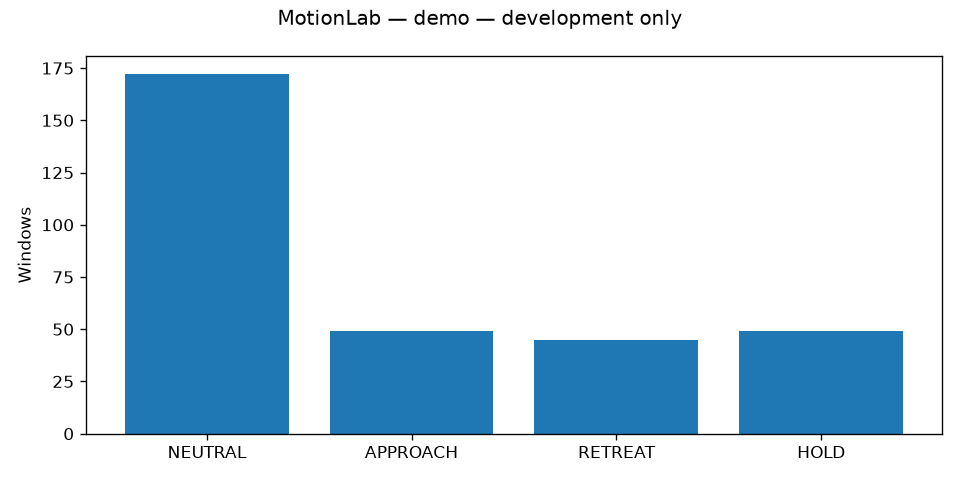

Janelas por classe: {'NEUTRAL': 172, 'HOLD': 49, 'RETREAT': 45, 'APPROACH': 49}. Desbalanceamento exige F1-macro e suporte por classe.

### Figura 2

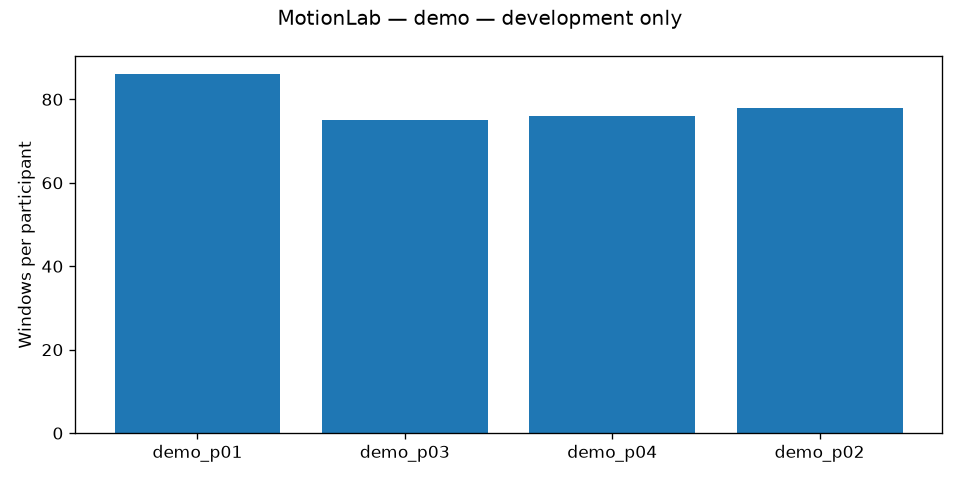

4 participantes no desenvolvimento; contagens {'demo_p01': 86, 'demo_p03': 75, 'demo_p04': 76, 'demo_p02': 78}. Janelas sobrepostas não são observações independentes; a unidade de generalização é o grupo.

### Figura 3

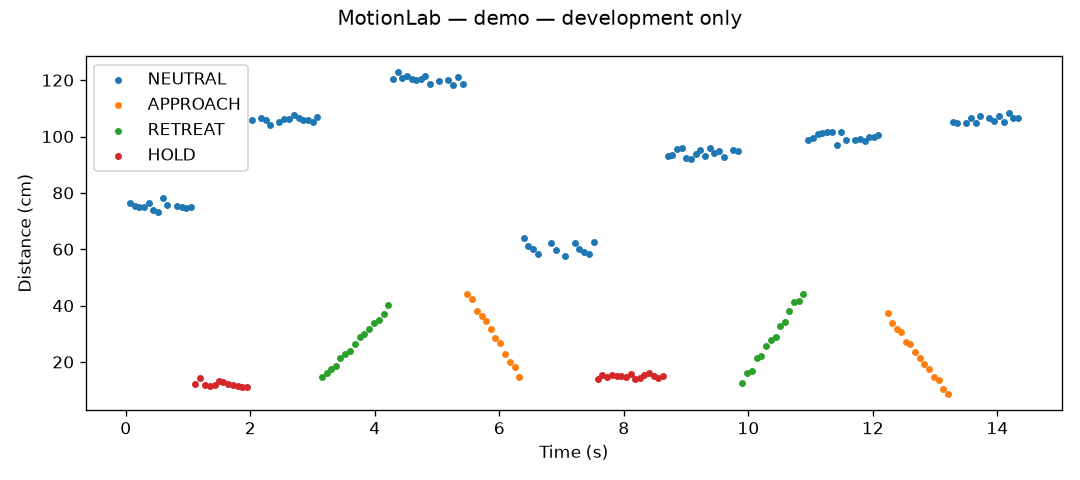

Sessão ilustrativa mqtt_demo_p01_42_6160d119, 191 amostras. Rótulos vêm do cronograma solicitado; não comprovam que a pessoa executou o gesto corretamente. Inspecionar transições antes de interpretar erros.

### Figura 4

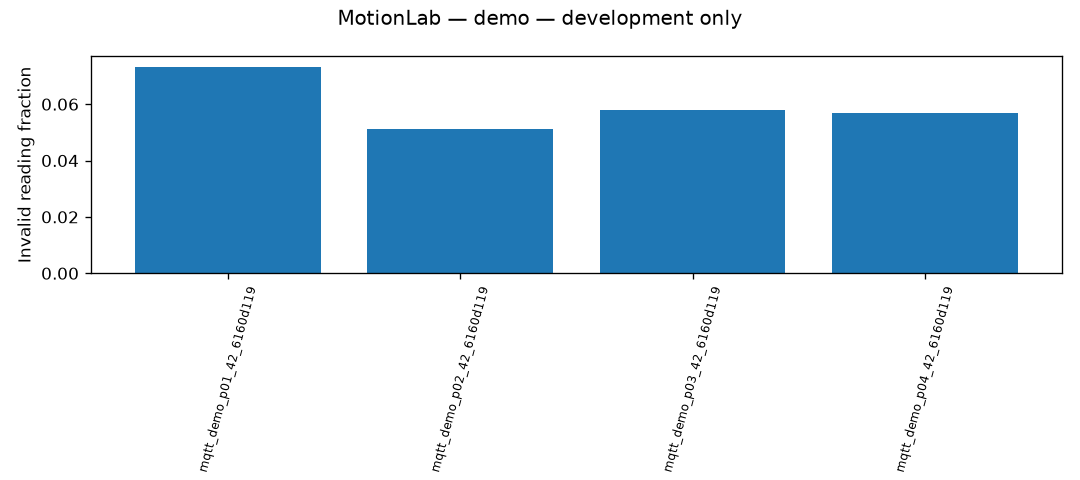

Fração inválida por sessão: {'mqtt_demo_p01_42_6160d119': 0.073, 'mqtt_demo_p02_42_6160d119': 0.051, 'mqtt_demo_p03_42_6160d119': 0.058, 'mqtt_demo_p04_42_6160d119': 0.057}. Timeouts são tratados causalmente; alta perda pode mudar a distribuição e gerar falsos acionamentos.

### Figura 5

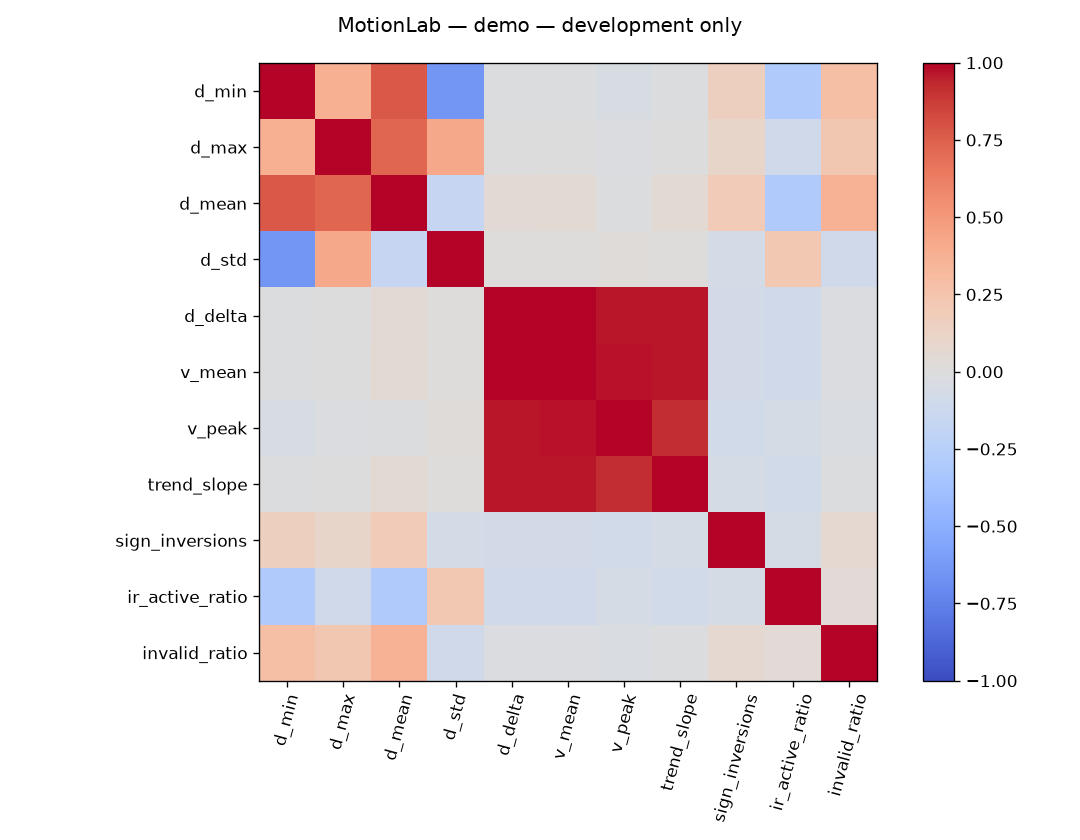

Maior correlação absoluta: v_mean × d_delta = 1.000. Redundância pode favorecer modelos compactos; correlação não estabelece causalidade. Features constantes aparecem como zero.

## Baselines, comparação, estabilidade e limites

A árvore de profundidade 1 é um baseline aprendido simples e de baixa capacidade, separado da árvore, floresta e MLP comparados. As regras são uma referência de domínio adicional, sem treino estatístico. A grade 3/5/7 da árvore é pequena, explícita e compatível com o orçamento embarcado. GroupKFold e LOGO preservam os participantes; quando os números de folds coincidem são a mesma partição, não duas evidências independentes. A CV reutilizada no tuning é descritiva. O teste externo não escolhe hiperparâmetros. Diferenças entre treino, validação e teste abaixo ajudam a investigar sobreajuste; escores baixos em todos sugerem capacidade insuficiente ou dados difíceis, sem diagnóstico causal automático.

In [3]:
from sklearn.metrics import f1_score
from ml.training.splitter import windows_to_xy
from ml.training.trainer import load_trained_bundle
report = json.loads((RUN / 'evaluation.json').read_text(encoding='utf-8'))
X_train, y_train = windows_to_xy(split.train)
for name, metrics in report['models'].items():
    bundle = load_trained_bundle(RUN / 'models' / (name + '.joblib'))
    train_f1 = float(f1_score(y_train, bundle.estimator.predict(X_train), labels=list(range(4)), average='macro', zero_division=0))
    cv = manifest['validation']['group_kfold']['models'][name]
    print(json.dumps({'model': name, 'train_f1': train_f1, 'validation_f1': metrics['val_f1_macro'], 'test_f1': metrics['test_f1_macro'], 'train_minus_validation': train_f1 - metrics['val_f1_macro'], 'cv_mean': cv['f1_macro_mean'], 'cv_std': cv['f1_macro_std'], 'valid_folds': cv['valid_folds'], 'far_status': metrics['false_activation_rate_neutral_status']}, ensure_ascii=False))
print('Tuning:', json.dumps(manifest['tuning'], ensure_ascii=False))

{"model": "rule_baseline", "train_f1": 0.5056607341933428, "validation_f1": 0.5253, "test_f1": 0.5718, "train_minus_validation": -0.019639265806657202, "cv_mean": 0.5092112451703625, "cv_std": 0.01278164133844316, "valid_folds": 4, "far_status": "evaluated"}
{"model": "decision_tree", "train_f1": 0.9308541964009829, "validation_f1": 0.7379, "test_f1": 0.5961, "train_minus_validation": 0.19295419640098288, "cv_mean": 0.7151241917232359, "cv_std": 0.0360710019260787, "valid_folds": 4, "far_status": "evaluated"}
{"model": "random_forest", "train_f1": 0.9715525012072327, "validation_f1": 0.8729, "test_f1": 0.8466, "train_minus_validation": 0.09865250120723268, "cv_mean": 0.8054563872357217, "cv_std": 0.10210655463307147, "valid_folds": 4, "far_status": "evaluated"}
{"model": "mlp_compact", "train_f1": 0.9929353233830845, "validation_f1": 0.8962, "test_f1": 0.9713, "train_minus_validation": 0.09673532338308455, "cv_mean": 0.8554923410415309, "cv_std": 0.0440221833548459, "valid_folds": 4, "

## Matrizes de confusão e comparação dos modelos

Linhas são rótulos conhecidos no cenário simulado; colunas são previsões. Fora da diagonal estão os erros observados. As métricas de teste são descritivas desta execução reservada.

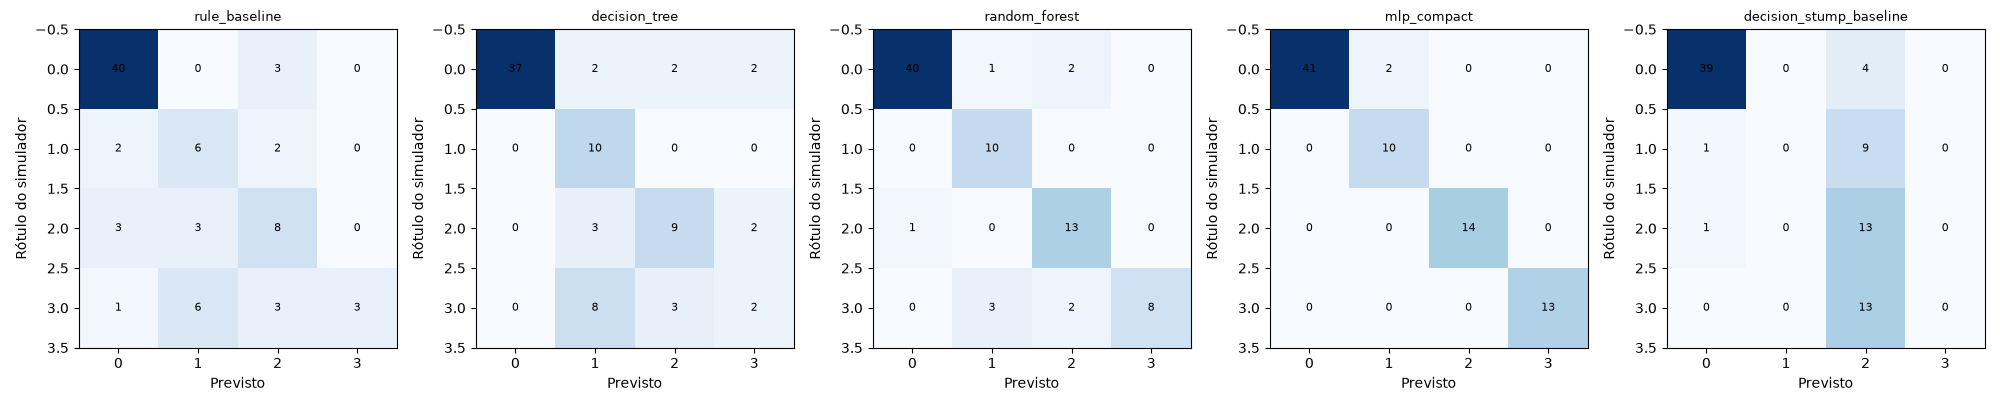

## Rastreabilidade e interpretação crítica

Examinar a classe com menor recall e as confusões recorrentes, além de F1 agregado. A proximidade entre regras e modelos no simulador pode refletir o próprio gerador; não comprova vantagem de ML em pessoas reais. Desvio entre folds não é intervalo de confiança. A seleção usa validação e estimativas de memória; a latência é medida em Python no host do experimento. Não há benchmark físico. O run MLflow abaixo contém parâmetros, modelos e artefatos desta execução.

In [4]:
for name, metrics in report['models'].items():
    weakest = min(metrics['per_class'].items(), key=lambda item: item[1]['recall'])
    print(name, 'menor recall:', weakest[0], weakest[1])
print(json.dumps(manifest['tracking'], indent=2))

rule_baseline menor recall: HOLD {'precision': 1.0, 'recall': 0.2308, 'f1': 0.375, 'support': 13}
decision_tree menor recall: HOLD {'precision': 0.3333, 'recall': 0.1538, 'f1': 0.2105, 'support': 13}
random_forest menor recall: HOLD {'precision': 1.0, 'recall': 0.6154, 'f1': 0.7619, 'support': 13}
mlp_compact menor recall: NEUTRAL {'precision': 1.0, 'recall': 0.9535, 'f1': 0.9762, 'support': 43}
decision_stump_baseline menor recall: APPROACH {'precision': 0.0, 'recall': 0.0, 'f1': 0.0, 'support': 10}
{
  "status": "logged",
  "run_id": "2891cdd2ced34bb5bbe337e096d59768",
  "experiment_id": "1",
  "tracking_uri": "http://mlflow:5000"
}
